# 🚢 Investigación integradora: ¿Quién sobrevivió al Titanic?

**Capítulo 4 — Probabilidad y Estadística (SIC)**

Un solo dataset, una sola investigación. Cada herramienta del capítulo aparece **porque la pregunta anterior la necesita**, no porque toque en el programa.

> **Pregunta madre:** ¿Qué podemos aprender sobre la supervivencia en el Titanic a partir de una muestra de pasajeros? ¿Qué características parecen estar asociadas con ella? ¿Podemos construir un modelo que la prediga y, sobre todo, **podemos confiar en él**?

### Mapa de la investigación

| Parte | Pregunta | Unidad del PDF |
|---|---|---|
| 0 | ¿Qué tenemos? Individuo, variable, feature, target | Intro / 3.1 |
| 1 | ¿Cómo se combinan los eventos? Condicional, independencia, Bayes | 1.1 – 1.2 |
| 2 | Variable aleatoria, esperanza, varianza; Bernoulli, Binomial, Poisson | 1.3 – 1.4 |
| 3 | Distribuciones continuas: uniforme, normal, $\chi^2$, $t$, $F$ | 2.1 |
| 4 | Covarianza, correlación y dependencia | 2.2 |
| 5 | Estadística descriptiva: cuantiles y boxplot | 3.1 |
| 6 | Muestreo, LGN, TCL y error estándar | 3.2 |
| 7 | Estimación: sesgo, eficiencia, consistencia e intervalos de confianza | 3.3 |
| 8 | Pruebas de hipótesis: Z, t, ANOVA, $\chi^2$, F | 4.1 – 4.2 |
| 9 | Machine Learning: features → target | Puente al capítulo siguiente |
| 10 | **Sesgo**: del estimador, de la muestra, sesgo-varianza y sesgo algorítmico | Transversal |

**Vocabulario que usamos todo el tiempo**

- **Variable**: propiedad medida (`Age`, `Fare`, `Sex`…).
- **Feature**: variable usada como entrada $X$. **Target**: variable que queremos explicar o predecir $Y$.
- **Parámetro** ($\mu,\sigma,p$): número real de la población, desconocido. **Estadístico** ($\bar x,s,\hat p$): número calculado con la muestra.
- **Parámetro aprendido** ($\beta, w, b$): lo ajusta el algoritmo. **Hiperparámetro** (`max_depth`, `C`): lo elegimos nosotros.

## Parte 0 — ¿Qué tenemos?

`titanic.csv` es **nuestra observación parcial de una realidad**. Antes de calcular nada: ¿qué es una fila? ¿Qué es una columna?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import (binom, poisson, norm, uniform, chi2, f as f_dist, t as t_dist,
                         ttest_1samp, ttest_ind, ttest_rel, f_oneway, chisquare,
                         chi2_contingency, pearsonr)

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(URL)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Para pensar**

1. ¿Qué representa una fila? ¿Cuál es nuestra población y cuál es nuestra muestra?
2. Clasificá cada columna: ¿cuantitativa discreta, continua, categórica nominal u ordinal?
3. Si quisiéramos **predecir** `Survived`, ¿cuál es el target y cuáles podrían ser los features?

> 🔎 *Pista de sesgo (la retomamos en la Parte 10):* ¿alguien nos garantizó que estos pasajeros son **todos** los que viajaban? Fijate en cuántas filas hay y en cuántos valores faltan.

In [3]:
print("Filas:", len(df))
print("\nValores faltantes por columna:")
print(df.isna().sum())

Filas: 891

Valores faltantes por columna:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## Parte 1 — Probabilidad: eventos, condicional, independencia y Bayes

*Unidad 1.1 – 1.2.* Elegimos **un pasajero al azar**. Definimos eventos con máscaras booleanas:

- $S$: sobrevivió. $F$: es mujer. $M$: es varón. $C_1$: viajaba en primera clase.

**Probabilidad frecuentista:** $P(A)\approx \dfrac{\text{casos favorables}}{\text{casos totales}}$. En pandas, la media de una máscara booleana *es* esa frecuencia.

In [4]:
S  = df["Survived"] == 1
F  = df["Sex"] == "female"
M  = df["Sex"] == "male"
C1 = df["Pclass"] == 1

P = lambda evento: evento.mean()      # frecuencia relativa de un evento

print(f"P(S)     = {P(S):.3f}")
print(f"P(F)     = {P(F):.3f}")
print(f"P(C1)    = {P(C1):.3f}")

P(S)     = 0.384
P(F)     = 0.352
P(C1)    = 0.242


### 1.1 Complemento y regla de la suma

$P(\bar A)=1-P(A)$ y $P(A\cup B)=P(A)+P(B)-P(A\cap B)$

In [5]:
print(f"P(no S) directo    = {P(~S):.3f}   |   1 - P(S) = {1 - P(S):.3f}")
print(f"P(F ∪ C1) directo  = {P(F | C1):.3f}")
print(f"P(F)+P(C1)-P(F∩C1) = {P(F) + P(C1) - P(F & C1):.3f}")

P(no S) directo    = 0.616   |   1 - P(S) = 0.616
P(F ∪ C1) directo  = 0.489
P(F)+P(C1)-P(F∩C1) = 0.489


### 1.2 Probabilidad condicional

$P(S\mid F)=\dfrac{P(S\cap F)}{P(F)}$ — "dentro del universo de las mujeres, ¿qué fracción sobrevivió?"

In [6]:
print(f"P(S | F) = P(S∩F)/P(F) = {P(S & F) / P(F):.3f}")
print(f"P(S | M) = P(S∩M)/P(M) = {P(S & M) / P(M):.3f}")
print(f"P(S | C1) = {P(S & C1) / P(C1):.3f}")

# Tabla conjunta: cada celda es P(Sex ∩ Survived)
pd.crosstab(df["Sex"], df["Survived"], normalize="all").round(3)

P(S | F) = P(S∩F)/P(F) = 0.742
P(S | M) = P(S∩M)/P(M) = 0.189
P(S | C1) = 0.630


Survived,0,1
Sex,,
female,0.091,0.262
male,0.525,0.122


### 1.3 Independencia

$A$ y $B$ son independientes si $P(A\cap B)=P(A)\,P(B)$. ¿Sexo y supervivencia lo son?

In [7]:
print(f"P(S ∩ F)    = {P(S & F):.3f}")
print(f"P(S) · P(F) = {P(S) * P(F):.3f}")
print("\n¿Se parecen? Si no, saber el sexo cambia la probabilidad de sobrevivir → NO son independientes.")

P(S ∩ F)    = 0.262
P(S) · P(F) = 0.135

¿Se parecen? Si no, saber el sexo cambia la probabilidad de sobrevivir → NO son independientes.


### 1.4 Probabilidad total y Teorema de Bayes

$P(S)=P(S\mid F)P(F)+P(S\mid M)P(M)$ y

$$P(F\mid S)=\frac{P(S\mid F)\,P(F)}{P(S)}$$

Pregunta: *sabiendo que una persona sobrevivió, ¿qué probabilidad hay de que sea mujer?* (Es distinto de $P(S\mid F)$: **invertir el condicionamiento cambia la pregunta**.)

In [8]:
P_S_F, P_S_M = P(S & F) / P(F), P(S & M) / P(M)

print(f"Prob. total: {P_S_F * P(F) + P_S_M * P(M):.3f}  (debe coincidir con P(S) = {P(S):.3f})")

bayes = P_S_F * P(F) / P(S)
print(f"\nBayes     P(F | S) = {bayes:.3f}")
print(f"Directo   P(F | S) = {P(F & S) / P(S):.3f}")
print(f"\nOjo:      P(S | F) = {P_S_F:.3f}  ≠  P(F | S) = {bayes:.3f}")

Prob. total: 0.384  (debe coincidir con P(S) = 0.384)

Bayes     P(F | S) = 0.681
Directo   P(F | S) = 0.681

Ojo:      P(S | F) = 0.742  ≠  P(F | S) = 0.681


## Parte 2 — Variable aleatoria, Bernoulli, Binomial y Poisson

*Unidad 1.3 – 1.4.*

### 2.1 Bernoulli y sus momentos

$X=1$ si sobrevive, $0$ si no. $X\sim\text{Bernoulli}(p)$ con $E[X]=p$ y $\mathrm{Var}[X]=p(1-p)$.

Y acá aparece la primera tensión del curso: **no conocemos $p$**, solo tenemos $\hat p$.

In [9]:
p_hat = df["Survived"].mean()

print(f"p̂ = {p_hat:.4f}")
print(f"E[X]   teórica = p       = {p_hat:.4f}")
print(f"Var[X] teórica = p(1-p)  = {p_hat * (1 - p_hat):.4f}")
print(f"Var muestral (ddof=0)    = {df['Survived'].var(ddof=0):.4f}")

p̂ = 0.3838
E[X]   teórica = p       = 0.3838
Var[X] teórica = p(1-p)  = 0.2365
Var muestral (ddof=0)    = 0.2365


### 2.2 Binomial

Si seleccionamos $n=20$ pasajeros **independientes** y cada uno sobrevive con probabilidad $p$, el número de sobrevivientes es $Y\sim\text{Binomial}(20,p)$.

P(Y = 8)   = 0.1777
P(Y ≤ 8)   = 0.6527
P(Y ≥ 10)  = 0.1997      # sf(k) = P(Y > k)
E[Y] = np = 7.68,   Var[Y] = np(1-p) = 4.73


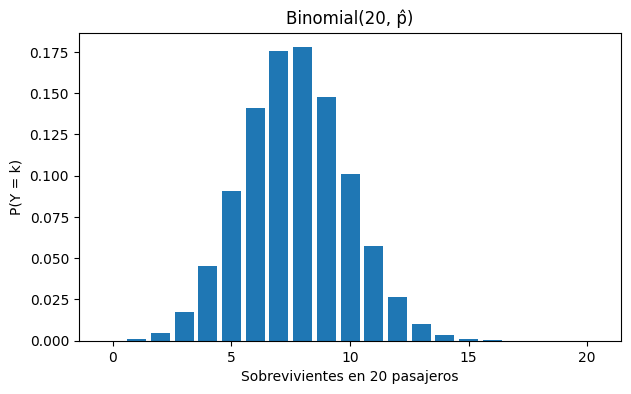


Simulación:  media = 7.66   varianza = 4.67


In [10]:
n = 20
print(f"P(Y = 8)   = {binom.pmf(8, n, p_hat):.4f}")
print(f"P(Y ≤ 8)   = {binom.cdf(8, n, p_hat):.4f}")
print(f"P(Y ≥ 10)  = {binom.sf(9, n, p_hat):.4f}      # sf(k) = P(Y > k)")
print(f"E[Y] = np = {n * p_hat:.2f},   Var[Y] = np(1-p) = {n * p_hat * (1 - p_hat):.2f}")

k = np.arange(0, n + 1)
plt.bar(k, binom.pmf(k, n, p_hat))
plt.xlabel("Sobrevivientes en 20 pasajeros")
plt.ylabel("P(Y = k)")
plt.title("Binomial(20, p̂)")
plt.show()

# ¿Coincide con un experimento? Simulamos 10 000 grupos de 20 pasajeros
sim = binom.rvs(n, p_hat, size=10_000, random_state=1)
print(f"\nSimulación:  media = {sim.mean():.2f}   varianza = {sim.var():.2f}")

### 2.3 Poisson: contar eventos

Poisson modela **conteos** con $E[X]=\mathrm{Var}[X]=\lambda$. Probemos con `SibSp` (hermanos/cónyuges a bordo).

> ⚠️ **Poisson exige media ≈ varianza.** Si los datos no lo cumplen, el modelo no sirve. Comprobarlo es parte del trabajo.

media = 0.523   varianza = 1.216


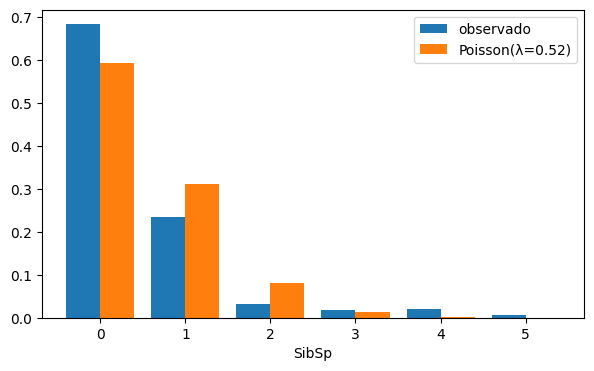

In [11]:
lam = df["SibSp"].mean()
print(f"media = {lam:.3f}   varianza = {df['SibSp'].var():.3f}")

ks = np.arange(0, 6)
obs = df["SibSp"].value_counts(normalize=True).reindex(ks, fill_value=0)
teo = poisson.pmf(ks, lam)

plt.bar(ks - 0.2, obs, width=0.4, label="observado")
plt.bar(ks + 0.2, teo, width=0.4, label=f"Poisson(λ={lam:.2f})")
plt.legend(); plt.xlabel("SibSp"); plt.show()

**Para pensar:** ¿la varianza es parecida a la media? ¿Qué te dice eso del ajuste? (Cuando la varianza supera a la media hablamos de *sobredispersión*.)

## Parte 3 — Distribuciones continuas

*Unidad 2.1.* En continuas no hay $P(X=x)$: hay **densidad** y **áreas**. $P(a<X<b)=\int_a^b f(x)\,dx$.

### 3.1 Uniforme (el caso más simple)

Ejemplo del PDF: la vida útil de una bombilla es uniforme entre 10 000 y 20 000 horas.

In [12]:
bombilla = uniform(loc=10_000, scale=10_000)     # uniform(loc=a, scale=b-a)
print(f"P(X < 12 000)           = {bombilla.cdf(12_000):.3f}")
print(f"P(13 000 < X < 18 000)  = {bombilla.cdf(18_000) - bombilla.cdf(13_000):.3f}")
print(f"E[X] = {bombilla.mean():.0f}   Var[X] = {bombilla.var():.0f}")

P(X < 12 000)           = 0.200
P(13 000 < X < 18 000)  = 0.500
E[X] = 15000   Var[X] = 8333333


### 3.2 Normal y estandarización

Modelamos la edad con $N(\mu,\sigma^2)$. Para consultar áreas de **cualquier** normal usamos el traductor universal:

$$Z=\frac{X-\mu}{\sigma}\sim N(0,1)$$

Flujo de trabajo: **problema → Z → Normal estándar → área**.

Modelo normal: 0.509   |   Datos reales: 0.521

Z(60 años) = 2.09   → P(X > 60) = 0.0184
Z con 95 % de área a la izquierda = 1.645
Edad correspondiente = 53.6


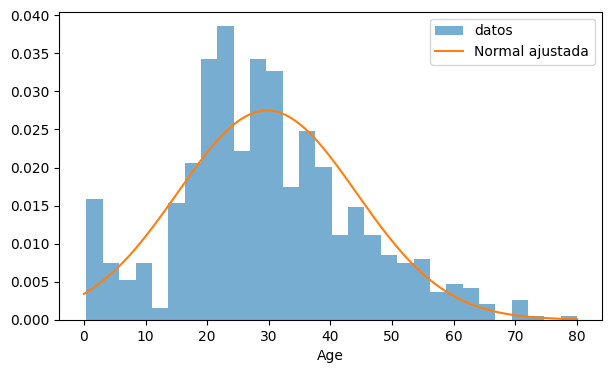

In [13]:
ages = df["Age"].dropna()
mu, sigma = ages.mean(), ages.std(ddof=0)

# ¿Qué proporción de pasajeros tiene entre 20 y 40 años?
teorica  = norm.cdf(40, mu, sigma) - norm.cdf(20, mu, sigma)
empirica = ((ages > 20) & (ages < 40)).mean()
print(f"Modelo normal: {teorica:.3f}   |   Datos reales: {empirica:.3f}")

# Estandarizar: ¿qué tan lejos de lo típico está alguien de 60?
z = (60 - mu) / sigma
print(f"\nZ(60 años) = {z:.2f}   → P(X > 60) = {norm.sf(z):.4f}")

# Camino inverso: dado un área, ¿qué Z? (la edad que deja 95 % por debajo)
print(f"Z con 95 % de área a la izquierda = {norm.ppf(0.95):.3f}")
print(f"Edad correspondiente = {norm.ppf(0.95, mu, sigma):.1f}")

x = np.linspace(0, 80, 300)
plt.hist(ages, bins=30, density=True, alpha=0.6, label="datos")
plt.plot(x, norm.pdf(x, mu, sigma), label="Normal ajustada")
plt.legend(); plt.xlabel("Age"); plt.show()

**Para pensar:** la normal ajusta *más o menos*. ¿Dónde falla? (Mirá la cola izquierda: no hay edades negativas, y hay un pico de bebés.) Este desajuste hace que el TCL de la Parte 6 sea tan potente.

### 3.3 $\chi^2$, $t$ y $F$: de dónde salen

Las usamos como tests más adelante, pero **son distribuciones construidas a partir de normales**. Las fabricamos por simulación:

- $\chi^2_k=Z_1^2+\dots+Z_k^2$
- $t_k=\dfrac{Z}{\sqrt{\chi^2_k/k}}$
- $F_{d_1,d_2}=\dfrac{\chi^2_{d_1}/d_1}{\chi^2_{d_2}/d_2}$

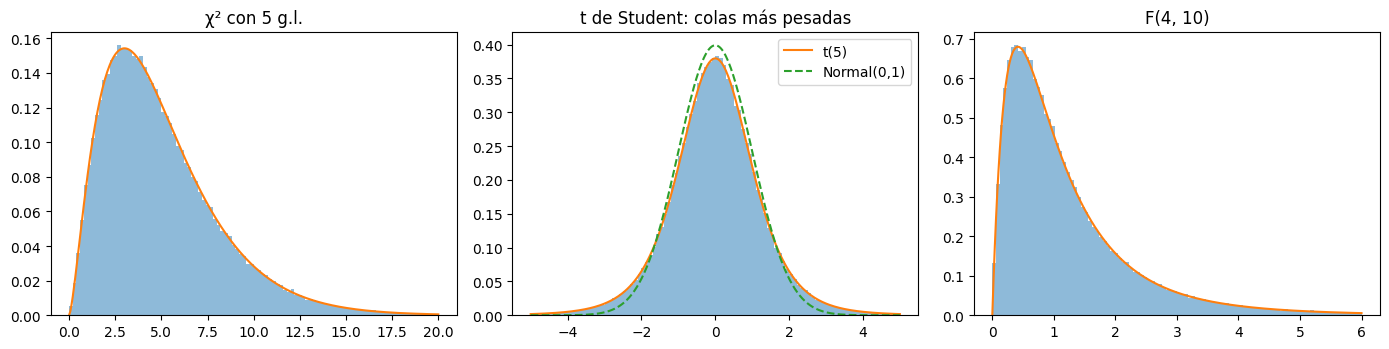

In [14]:
N_SIM = 200_000
k, d1, d2 = 5, 4, 10

Z = rng.standard_normal((N_SIM, k))
chi_sim = (Z ** 2).sum(axis=1)                              # suma de k normales²
t_sim   = rng.standard_normal(N_SIM) / np.sqrt(rng.chisquare(k, N_SIM) / k)
F_sim   = (rng.chisquare(d1, N_SIM) / d1) / (rng.chisquare(d2, N_SIM) / d2)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

xs = np.linspace(0, 20, 300)
ax[0].hist(chi_sim, bins=100, range=(0, 20), density=True, alpha=.5)
ax[0].plot(xs, chi2.pdf(xs, k)); ax[0].set_title(f"χ² con {k} g.l.")

xs = np.linspace(-5, 5, 300)
ax[1].hist(t_sim, bins=100, range=(-5, 5), density=True, alpha=.5)
ax[1].plot(xs, t_dist.pdf(xs, k), label=f"t({k})")
ax[1].plot(xs, norm.pdf(xs), "--", label="Normal(0,1)")
ax[1].legend(); ax[1].set_title("t de Student: colas más pesadas")

xs = np.linspace(0, 6, 300)
ax[2].hist(F_sim, bins=100, range=(0, 6), density=True, alpha=.5)
ax[2].plot(xs, f_dist.pdf(xs, d1, d2)); ax[2].set_title(f"F({d1}, {d2})")
plt.tight_layout(); plt.show()

**Para pensar:** ¿qué pasa con la $t$ cuando los grados de libertad crecen? (Probá `k = 100`.)

## Parte 4 — Dos variables a la vez: covarianza, correlación y dependencia

*Unidad 2.2.*

$$\mathrm{Cov}(X,Y)=E[(X-\mu_X)(Y-\mu_Y)]\qquad \rho=\frac{\mathrm{Cov}(X,Y)}{\sigma_X\sigma_Y}\in[-1,1]$$

La covarianza depende de las unidades. La correlación no.

Covarianza y correlación:
         Age     Fare
Age   211.02    73.85
Fare   73.85  2800.41 

        Age   Fare
Age   1.000  0.096
Fare  0.096  1.000 

r = 0.096   p-valor = 0.0102


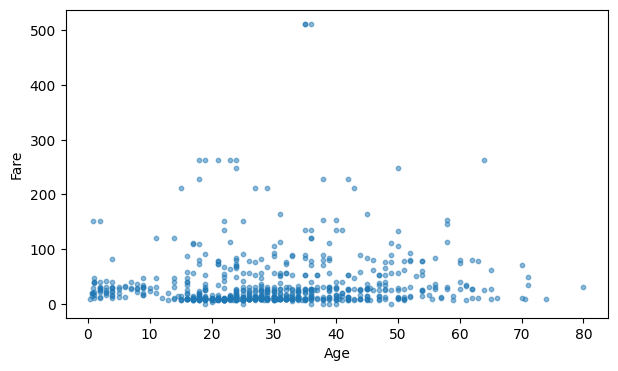

In [15]:
d = df[["Age", "Fare"]].dropna()
print("Covarianza y correlación:")
print(d.cov().round(2), "\n")
print(d.corr().round(3), "\n")

r, p_r = pearsonr(d["Age"], d["Fare"])
print(f"r = {r:.3f}   p-valor = {p_r:.4f}")

plt.scatter(d["Age"], d["Fare"], s=10, alpha=.5)
plt.xlabel("Age"); plt.ylabel("Fare"); plt.show()

### Correlación cero **no** significa independencia

$\rho$ mide solo la relación **lineal**. Construimos una dependencia perfecta con correlación casi nula:

corr(x, y) = -0.005


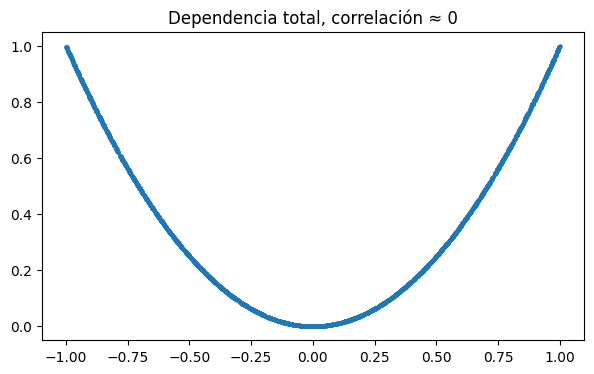

In [16]:
x = rng.uniform(-1, 1, 2000)
y = x ** 2                                   # y depende 100 % de x

print(f"corr(x, y) = {np.corrcoef(x, y)[0, 1]:.3f}")
plt.scatter(x, y, s=5); plt.title("Dependencia total, correlación ≈ 0"); plt.show()

## Parte 5 — Estadística descriptiva: cuantiles y boxplot

*Unidad 3.1.* Resumimos la muestra con **estadísticos**: $\bar x$, $s^2$, $s$, $\hat p$, mediana, cuartiles.

In [17]:
print("Estadísticos de Age")
print(f"  media     x̄  = {ages.mean():.2f}")
print(f"  mediana       = {ages.median():.2f}")
print(f"  varianza  s² = {ages.var(ddof=1):.2f}")
print(f"  desvío    s  = {ages.std(ddof=1):.2f}")

q = ages.quantile([0, .25, .5, .75, 1])
print("\nCuantiles:\n", q)
iqr = q[.75] - q[.25]
print(f"\nIQR = {iqr:.1f}   → límites de outliers: [{q[.25] - 1.5 * iqr:.1f}, {q[.75] + 1.5 * iqr:.1f}]")

Estadísticos de Age
  media     x̄  = 29.70
  mediana       = 28.00
  varianza  s² = 211.02
  desvío    s  = 14.53

Cuantiles:
 0.00     0.420
0.25    20.125
0.50    28.000
0.75    38.000
1.00    80.000
Name: Age, dtype: float64

IQR = 17.9   → límites de outliers: [-6.7, 64.8]


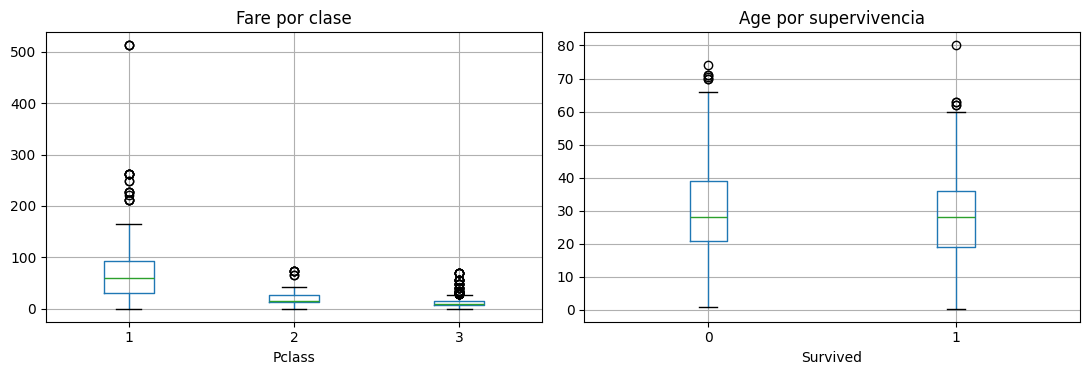

Asimetría de Fare: 4.79  (>0 → cola larga a la derecha)


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="Fare", by="Pclass", ax=ax[0]); ax[0].set_title("Fare por clase")
df.boxplot(column="Age", by="Survived", ax=ax[1]); ax[1].set_title("Age por supervivencia")
plt.suptitle(""); plt.tight_layout(); plt.show()

print(f"Asimetría de Fare: {df['Fare'].skew():.2f}  (>0 → cola larga a la derecha)")

**Para pensar:** en `Fare`, ¿conviene resumir con la media o con la mediana? ¿Por qué?

## Parte 6 — La montaña desconocida: muestreo, LGN y TCL

*Unidad 3.2.* Truco didáctico: tratamos las **714 edades conocidas como "población"**. Nosotros, como docentes, conocemos $\mu$ y $\sigma$. Los estudiantes trabajan con **una muestra** y deben acercarse a ellos.

In [19]:
population = ages.reset_index(drop=True)
pop = population.to_numpy()
mu_pop, sigma_pop = pop.mean(), pop.std()          # parámetros (ddof=0)

muestra = rng.choice(pop, size=30, replace=False)
print(f"PARÁMETRO   μ = {mu_pop:.2f}")
print(f"ESTADÍSTICO x̄ = {muestra.mean():.2f}   (n = 30)")
print("\nParámetro vs. estadístico: ahora se ven.")

PARÁMETRO   μ = 29.70
ESTADÍSTICO x̄ = 26.48   (n = 30)

Parámetro vs. estadístico: ahora se ven.


### 6.1 Ley de los Grandes Números

*Una* muestra que va creciendo: $n\uparrow \Rightarrow \bar X_n\to\mu$.

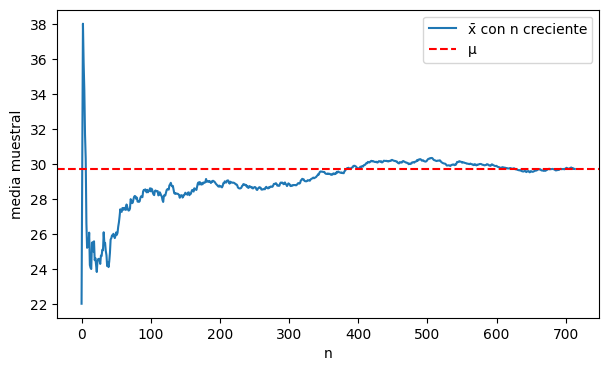

n =   5  →  x̄ = 37.80
n =  10  →  x̄ = 15.35
n =  30  →  x̄ = 34.05
n =  50  →  x̄ = 31.69
n = 100  →  x̄ = 32.45
n = 300  →  x̄ = 28.87


In [20]:
barajada = rng.permutation(pop)
media_acumulada = np.cumsum(barajada) / np.arange(1, len(barajada) + 1)

plt.plot(media_acumulada, label="x̄ con n creciente")
plt.axhline(mu_pop, color="red", ls="--", label="μ")
plt.xlabel("n"); plt.ylabel("media muestral"); plt.legend(); plt.show()

for n in [5, 10, 30, 50, 100, 300]:
    print(f"n = {n:3d}  →  x̄ = {rng.choice(pop, n, replace=False).mean():.2f}")

### 6.2 Teorema del Límite Central

**Cambio de pregunta.** Antes: *una* muestra que crece. Ahora: **muchas muestras distintas del mismo tamaño** $n$. ¿Cómo se distribuye $\bar X$?

n =   1   sd de las medias = 14.48   σ/√n = 14.52
n =   5   sd de las medias = 6.55   σ/√n = 6.49
n =  30   sd de las medias = 2.66   σ/√n = 2.65
n = 100   sd de las medias = 1.46   σ/√n = 1.45


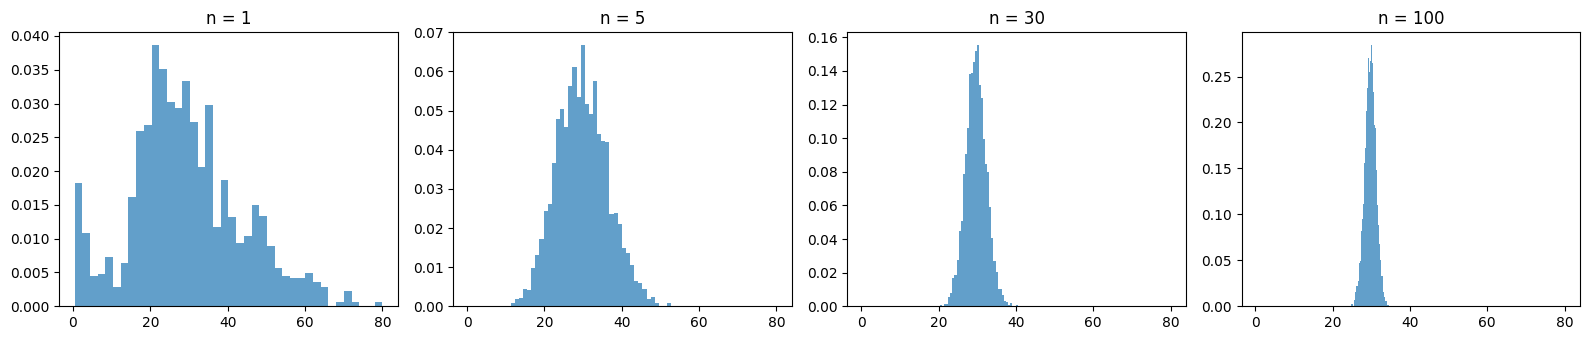

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
for ax, n in zip(axes, [1, 5, 30, 100]):
    medias = rng.choice(pop, size=(5000, n)).mean(axis=1)      # 5000 muestras de tamaño n
    ax.hist(medias, bins=40, density=True, alpha=.7)
    ax.set_title(f"n = {n}")
    print(f"n = {n:3d}   sd de las medias = {medias.std():.2f}   σ/√n = {sigma_pop / np.sqrt(n):.2f}")
plt.tight_layout(); plt.show()

La distribución de `Age` está sesgada, pero la de $\bar X$ **se vuelve Normal** al crecer $n$, centrada en $\mu$ con desvío $\sigma/\sqrt n$.

### 6.3 Error estándar

El **error estándar** es el desvío de la distribución muestral: mide *cuánto fluctúa el estimador de muestra en muestra*. En la práctica, con una sola muestra, se estima con $SE=s/\sqrt n$.

In [22]:
n = 30
medias_30 = rng.choice(pop, size=(5000, n)).mean(axis=1)
una_muestra = rng.choice(pop, n, replace=False)

print(f"Fluctuación real (sd de 5000 medias) = {medias_30.std():.3f}")
print(f"SE estimado con UNA muestra  s/√n    = {una_muestra.std(ddof=1) / np.sqrt(n):.3f}")

Fluctuación real (sd de 5000 medias) = 2.613
SE estimado con UNA muestra  s/√n    = 2.690


### 6.4 Z: ¿qué tan lejos está mi media de lo esperado?

$$Z=\frac{\bar x-\mu_0}{SE}$$

Con esto ya podemos *juzgar* una media. Es el puente directo a las pruebas de hipótesis.

In [23]:
mu0 = 30
xbar = una_muestra.mean()
se = una_muestra.std(ddof=1) / np.sqrt(n)
z = (xbar - mu0) / se
print(f"x̄ = {xbar:.2f}   Z = {z:.2f}   P(Z > |z|)·2 = {2 * norm.sf(abs(z)):.4f}")

x̄ = 28.63   Z = -0.51   P(Z > |z|)·2 = 0.6115


## Parte 7 — Estimación: ¿qué hace bueno a un estimador y cuánta confianza tenemos?

*Unidad 3.3.* Un **estimador** es una regla que convierte una muestra en una estimación de un parámetro. Un buen estimador cumple tres cosas:

1. **Insesgadez:** $E[\hat\theta]=\theta$ (no se equivoca sistemáticamente hacia un lado).
2. **Eficiencia:** entre los insesgados, el de **menor varianza**.
3. **Consistencia:** se acerca al parámetro cuando $n\to\infty$.

### 7.1 Insesgadez: ¿por qué dividimos por $n-1$?

Sesgo $=E[\hat\theta]-\theta$. Lo medimos repitiendo 20 000 veces el experimento de muestrear.

In [24]:
reps, n = 20_000, 10
X = rng.choice(pop, size=(reps, n))

var_n   = X.var(axis=1, ddof=0)          # divide por n
var_n_1 = X.var(axis=1, ddof=1)          # divide por n-1
sigma2 = pop.var()

print(f"σ² real                 = {sigma2:.2f}")
print(f"Promedio de s² (ddof=0) = {var_n.mean():.2f}   sesgo = {var_n.mean() - sigma2:+.2f}")
print(f"Promedio de s² (ddof=1) = {var_n_1.mean():.2f}   sesgo = {var_n_1.mean() - sigma2:+.2f}")

σ² real                 = 210.72
Promedio de s² (ddof=0) = 189.43   sesgo = -21.29
Promedio de s² (ddof=1) = 210.48   sesgo = -0.24


### 7.2 Eficiencia: media vs. mediana

Ambas estiman el centro. ¿Cuál fluctúa menos entre muestras?

In [25]:
M = rng.choice(pop, size=(5000, 30))
print(f"sd de las medias   = {M.mean(axis=1).std():.3f}")
print(f"sd de las medianas = {np.median(M, axis=1).std():.3f}   ← más variable: menos eficiente")

sd de las medias   = 2.659
sd de las medianas = 2.931   ← más variable: menos eficiente


### 7.3 Consistencia

Al crecer $n$, el estimador se concentra alrededor de $\mu$:

In [26]:
for n in [10, 30, 100, 300]:
    medias = rng.choice(pop, size=(3000, n)).mean(axis=1)
    print(f"n = {n:3d}   sd de x̄ = {medias.std():.3f}")

n =  10   sd de x̄ = 4.609
n =  30   sd de x̄ = 2.648
n = 100   sd de x̄ = 1.471
n = 300   sd de x̄ = 0.835


### 7.4 Intervalo de confianza de la media

Una estimación puntual ($\bar x$) casi nunca da en el blanco. El **intervalo de confianza** reconoce la incertidumbre:

$$\bar x \pm t_{\alpha/2,\,n-1}\cdot\frac{s}{\sqrt n}$$

(Con $\sigma$ desconocida se usa $t$, no Z.)

In [27]:
n = 30
muestra = rng.choice(pop, n, replace=False)
xbar, sem = muestra.mean(), stats.sem(muestra)          # sem = s/√n

print(f"x̄ = {xbar:.2f}   (μ real = {mu_pop:.2f})")
for conf in [0.90, 0.95, 0.99]:
    lo, hi = t_dist.interval(conf, df=n - 1, loc=xbar, scale=sem)
    print(f"IC {conf:.0%}: [{lo:.2f}, {hi:.2f}]   ancho = {hi - lo:.2f}")

x̄ = 29.82   (μ real = 29.70)
IC 90%: [24.60, 35.04]   ancho = 10.44
IC 95%: [23.53, 36.10]   ancho = 12.57
IC 99%: [21.35, 38.29]   ancho = 16.94


**Más confianza → intervalo más ancho.** No hay almuerzo gratis.

### ¿Qué significa realmente "95 % de confianza"?

No es "hay 95 % de probabilidad de que $\mu$ esté acá". Significa: **si repetimos el procedimiento muchas veces, ~95 % de los intervalos contienen a $\mu$**. Lo comprobamos:

In [28]:
reps, cubre = 2000, 0
for _ in range(reps):
    m = rng.choice(pop, n, replace=False)
    lo, hi = t_dist.interval(0.95, df=n - 1, loc=m.mean(), scale=stats.sem(m))
    cubre += (lo <= mu_pop <= hi)
print(f"Cobertura empírica: {cubre / reps:.1%}   (nominal 95 %)")

Cobertura empírica: 95.2%   (nominal 95 %)


### 7.5 ¿Cuántos datos necesito para un ancho dado?

Si quiero un margen de error $W$ (semiancho): $n=\left(\dfrac{z_{\alpha/2}\,s}{W}\right)^2$

In [29]:
W = 1.0                       # queremos x̄ ± 1 año
s = pop.std(ddof=1)
n_req = int(np.ceil((norm.ppf(0.975) * s / W) ** 2))
print(f"s = {s:.2f}   →   n necesario ≈ {n_req}")
print("Para reducir el margen a la mitad, ¿cuánto hay que aumentar n? (probá W = 0.5)")

s = 14.53   →   n necesario ≈ 811
Para reducir el margen a la mitad, ¿cuánto hay que aumentar n? (probá W = 0.5)


### 7.6 Intervalo para la correlación (transformada de Fisher) y para una proporción

La distribución de $r$ no es simétrica, así que se transforma: $z=\operatorname{arctanh}(r)$, con $SE=1/\sqrt{n-3}$, y se destransforma con $\tanh$.

In [30]:
d = df[["Age", "Fare"]].dropna()
r, _ = pearsonr(d["Age"], d["Fare"])
n_r = len(d)
zr, se_r = np.arctanh(r), 1 / np.sqrt(n_r - 3)
lo, hi = np.tanh(zr - norm.ppf(0.975) * se_r), np.tanh(zr + norm.ppf(0.975) * se_r)
print(f"r = {r:.3f}   IC 95 %: [{lo:.3f}, {hi:.3f}]")

# Proporción de sobrevivientes
p_hat, n_p = df["Survived"].mean(), len(df)
e = norm.ppf(0.975) * np.sqrt(p_hat * (1 - p_hat) / n_p)
print(f"p̂ = {p_hat:.3f}   IC 95 %: [{p_hat - e:.3f}, {p_hat + e:.3f}]")

r = 0.096   IC 95 %: [0.023, 0.168]
p̂ = 0.384   IC 95 %: [0.352, 0.416]


## Parte 8 — Pruebas de hipótesis

*Unidad 4.* La pregunta cambia otra vez:

> Ya sé describir mi muestra. **¿Puedo afirmar algo sobre la población?**

Una prueba de hipótesis contrasta una afirmación sobre un **parámetro** usando un **estadístico**.

### Receta (siempre la misma)

1. Plantear $H_0$ (no hay efecto) y $H_1$ (la cola: $\ne$, $<$ o $>$).
2. Elegir $\alpha$ (típicamente 0.05).
3. Calcular el **estadístico de prueba** (Z, t, F, $\chi^2$).
4. Obtener el **p-valor**: probabilidad de ver algo *al menos tan extremo* si $H_0$ fuese cierta.
5. Decidir: **p < α → rechazo $H_0$**; si no, *no rechazo* (no es "acepto").

In [31]:
def decidir(p, alpha=0.05):
    return f"p = {p:.4f}  →  " + ("RECHAZO H0" if p < alpha else "No rechazo H0")

### 8.1 Media de una muestra: $t$ de una muestra

$H_0:\mu=30$ vs. $H_1:\mu\ne30$. Como $\sigma$ es desconocida, el estadístico es $t=\dfrac{\bar x-\mu_0}{s/\sqrt n}$.

In [32]:
res = ttest_1samp(ages, popmean=30)                      # dos colas
print("Dos colas, μ0 = 30   :", res.statistic.round(3), decidir(res.pvalue))

# A mano, para ver que no es magia:
t_man = (ages.mean() - 30) / (ages.std(ddof=1) / np.sqrt(len(ages)))
print("t calculado a mano   :", round(t_man, 3))

# Cola derecha: H1: μ > 28
res = ttest_1samp(ages, popmean=28, alternative="greater")
print("Cola derecha, μ0 = 28:", res.statistic.round(3), decidir(res.pvalue))

# Cola izquierda: H1: μ < 31
res = ttest_1samp(ages, popmean=31, alternative="less")
print("Cola izquierda, μ0=31:", res.statistic.round(3), decidir(res.pvalue))

Dos colas, μ0 = 30   : -0.553 p = 0.5801  →  No rechazo H0
t calculado a mano   : -0.553
Cola derecha, μ0 = 28: 3.125 p = 0.0009  →  RECHAZO H0
Cola izquierda, μ0=31: -2.393 p = 0.0085  →  RECHAZO H0


**Para pensar:** ¿la dirección de $H_1$ cambia el p-valor? ¿Cuándo es legítimo elegir una cola antes de ver los datos?

### 8.2 Una proporción: prueba Z

$H_0:p=0.5$ ("sobrevive la mitad") vs. $H_1:p\ne0.5$. Con $n$ grande: $Z=\dfrac{\hat p-p_0}{\sqrt{p_0(1-p_0)/n}}$

In [33]:
p0, n_p = 0.5, len(df)
z = (df["Survived"].mean() - p0) / np.sqrt(p0 * (1 - p0) / n_p)
print(f"Z = {z:.2f}", decidir(2 * norm.sf(abs(z))))

Z = -6.93 p = 0.0000  →  RECHAZO H0


### 8.3 Dos grupos independientes: $t$ de Welch

$H_0:\mu_S=\mu_N$ (los sobrevivientes y los no sobrevivientes tenían la misma edad media).

In [34]:
sobrev = df.loc[df["Survived"] == 1, "Age"].dropna()
muertos = df.loc[df["Survived"] == 0, "Age"].dropna()
print(f"Edad media: sobrevivientes = {sobrev.mean():.2f}  |  no sobrevivientes = {muertos.mean():.2f}")

res = ttest_ind(sobrev, muertos, equal_var=False)
print("Dos colas  (≠):", decidir(res.pvalue))

res = ttest_ind(sobrev, muertos, equal_var=False, alternative="less")
print("Cola izq.  (S son más jóvenes):", decidir(res.pvalue))

Edad media: sobrevivientes = 28.34  |  no sobrevivientes = 30.63
Dos colas  (≠): p = 0.0412  →  RECHAZO H0
Cola izq.  (S son más jóvenes): p = 0.0206  →  RECHAZO H0


**Para pensar:** misma pregunta, dos colas distintas, dos p-valores distintos. ¿Qué significa decidir la cola *después* de mirar los datos?

> `equal_var=False` (Welch) no asume varianzas iguales. En 8.9 vemos cómo **verificar** ese supuesto con una prueba F.

### 8.4 Muestras pareadas: $t$ pareada

Se usa cuando **los mismos sujetos** se miden dos veces (antes/después). Titanic no tiene mediciones repetidas, así que acá usamos **datos sintéticos** (*solo* para esta prueba).

Idea clave: la t pareada es una t de una muestra sobre las **diferencias**.

In [35]:
# Sintético: nota de 40 estudiantes antes y después de una clase de repaso
antes = rng.normal(6.0, 1.5, 40)
despues = antes + rng.normal(0.6, 1.0, 40)

print("ttest_rel   :", decidir(ttest_rel(despues, antes, alternative="greater").pvalue))
print("1-muestra de las diferencias:",
      decidir(ttest_1samp(despues - antes, 0, alternative="greater").pvalue))

ttest_rel   : p = 0.0007  →  RECHAZO H0
1-muestra de las diferencias: p = 0.0007  →  RECHAZO H0


### 8.5 Más de dos grupos: ANOVA ($F$)

$H_0:\mu_1=\mu_2=\mu_3$ vs. $H_1$: *al menos una difiere*.

$$F=\frac{\text{variabilidad entre grupos}}{\text{variabilidad dentro de los grupos}}$$

In [36]:
g1, g2, g3 = [df.loc[df["Pclass"] == c, "Fare"].dropna() for c in (1, 2, 3)]
res = f_oneway(g1, g2, g3)
print(f"F = {res.statistic:.1f}", decidir(res.pvalue))

# ANOVA solo dice "alguna difiere". ¿Cuáles? → comparaciones post-hoc
print(stats.tukey_hsd(g1, g2, g3))

F = 242.3 p = 0.0000  →  RECHAZO H0
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     63.493     0.000    54.069    72.916
 (0 - 2)     70.479     0.000    62.809    78.149
 (1 - 0)    -63.493     0.000   -72.916   -54.069
 (1 - 2)      6.987     0.108    -1.133    15.106
 (2 - 0)    -70.479     0.000   -78.149   -62.809
 (2 - 1)     -6.987     0.108   -15.106     1.133



> ⚠️ `Fare` es muy asimétrica; ANOVA supone normalidad aproximada. Con muestras grandes el TCL ayuda, pero conviene mencionarlo.

### 8.6 Frecuencias: $\chi^2$ de una vía (bondad de ajuste)

$H_0$: la variable categórica sigue una distribución dada.
$\chi^2=\sum\dfrac{(O-E)^2}{E}$

In [37]:
# ¿Había igual cantidad de varones y mujeres?
obs = df["Sex"].value_counts()
res = chisquare(obs)                       # sin f_exp → todas las categorías igual de probables
print("Sexo 50/50:", decidir(res.pvalue))

# ¿Y si la distribución de clases hubiera sido 20 / 25 / 55 %?
obs = df["Pclass"].value_counts().sort_index()
esp = np.array([0.20, 0.25, 0.55]) * obs.sum()
res = chisquare(obs, f_exp=esp)
print("Clases 20/25/55:", decidir(res.pvalue))

Sexo 50/50: p = 0.0000  →  RECHAZO H0
Clases 20/25/55: p = 0.0006  →  RECHAZO H0


### 8.7 Frecuencias: $\chi^2$ de dos vías (independencia)

$H_0$: las dos variables categóricas son **independientes**. Compara frecuencias *observadas* contra las *esperadas si fueran independientes*.

> Esta es la misma tabla de contingencia de la Parte 1 — y, más adelante, la **matriz de confusión**.

In [38]:
def chi2_independencia(a, b):
    tabla = pd.crosstab(a, b)
    chi, p, gl, esperadas = chi2_contingency(tabla)
    v = np.sqrt(chi / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))     # V de Cramér
    print(tabla, "\n")
    print("Esperadas si fueran independientes:\n", pd.DataFrame(esperadas, index=tabla.index,
          columns=tabla.columns).round(1), "\n")
    print(f"χ² = {chi:.2f}  gl = {gl}  V de Cramér = {v:.2f}  ", decidir(p), "\n")

chi2_independencia(df["Sex"], df["Survived"])
chi2_independencia(df["Pclass"], df["Survived"])

Survived    0    1
Sex               
female     81  233
male      468  109 

Esperadas si fueran independientes:
 Survived      0      1
Sex                   
female    193.5  120.5
male      355.5  221.5 

χ² = 260.72  gl = 1  V de Cramér = 0.54   p = 0.0000  →  RECHAZO H0 

Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119 

Esperadas si fueran independientes:
 Survived      0      1
Pclass                
1         133.1   82.9
2         113.4   70.6
3         302.5  188.5 

χ² = 102.89  gl = 2  V de Cramér = 0.34   p = 0.0000  →  RECHAZO H0 



**Para pensar:** el p-valor dice *si* hay asociación. El V de Cramér dice *qué tan fuerte* es. ¿Cuál de las dos asociaciones es más fuerte?

### 8.8 Varianza de una población: $\chi^2$ de varianza

$H_0:\sigma^2=\sigma_0^2$, con $\chi^2=\dfrac{(n-1)s^2}{\sigma_0^2}\sim\chi^2_{n-1}$ bajo $H_0$.

In [39]:
n = len(ages)
s2 = ages.var(ddof=1)
sigma0_sq = 14 ** 2
stat = (n - 1) * s2 / sigma0_sq
p_two = 2 * min(chi2.cdf(stat, n - 1), chi2.sf(stat, n - 1))
print(f"χ² = {stat:.1f}   s = {np.sqrt(s2):.2f}   vs σ0 = 14", decidir(p_two))

χ² = 767.6   s = 14.53   vs σ0 = 14 p = 0.1530  →  No rechazo H0


### 8.9 Dos varianzas: prueba $F$ de razón de varianzas

$H_0:\sigma_1^2=\sigma_2^2$, con $F=s_1^2/s_2^2$.

In [40]:
edad_h = df.loc[df["Sex"] == "male", "Age"].dropna()
edad_m = df.loc[df["Sex"] == "female", "Age"].dropna()

F_stat = edad_h.var(ddof=1) / edad_m.var(ddof=1)
d1, d2 = len(edad_h) - 1, len(edad_m) - 1
p_two = 2 * min(f_dist.cdf(F_stat, d1, d2), f_dist.sf(F_stat, d1, d2))
print(f"F = {F_stat:.3f}", decidir(p_two))

F = 1.082 p = 0.4814  →  No rechazo H0


### 8.10 Mapa de decisión (input → output)

¿Qué test uso? Dos preguntas: **¿qué parámetro?** y **¿qué tipo de variable?**

In [41]:
mapa = pd.DataFrame([
    ["1 media vs. valor",           "1 cuantitativa",             "t de una muestra (Z si σ conocida)", "ttest_1samp"],
    ["1 proporción vs. valor",      "1 binaria",                  "Z de proporción",                    "manual con norm.sf"],
    ["2 medias, grupos distintos",  "cuantitativa + 2 grupos",    "t independiente (Welch)",            "ttest_ind(equal_var=False)"],
    ["2 medias, mismos sujetos",    "2 mediciones pareadas",      "t pareada",                          "ttest_rel"],
    ["3+ medias",                   "cuantitativa + 3+ grupos",   "ANOVA (F)",                          "f_oneway"],
    ["Distribución categórica",     "1 categórica",               "χ² bondad de ajuste",                "chisquare"],
    ["Asociación entre categóricas","2 categóricas",              "χ² de independencia",                "chi2_contingency"],
    ["1 varianza vs. valor",        "1 cuantitativa",             "χ² de varianza",                     "manual con chi2.cdf"],
    ["2 varianzas",                 "cuantitativa + 2 grupos",    "F de razón de varianzas",            "manual con f.cdf"],
], columns=["Pregunta", "Variables", "Test", "Función scipy"])
mapa

,Pregunta,Variables,Test,Función scipy
0,1 media vs. valor,1 cuantitativa,t de una muestra (Z si σ conocida),ttest_1samp
1,1 proporción vs. valor,1 binaria,Z de proporción,manual con norm.sf
2,"2 medias, grupos distintos",cuantitativa + 2 grupos,t independiente (Welch),ttest_ind(equal_var=False)
3,"2 medias, mismos sujetos",2 mediciones pareadas,t pareada,ttest_rel
4,3+ medias,cuantitativa + 3+ grupos,ANOVA (F),f_oneway
5,Distribución categórica,1 categórica,χ² bondad de ajuste,chisquare
6,Asociación entre categóricas,2 categóricas,χ² de independencia,chi2_contingency
7,1 varianza vs. valor,1 cuantitativa,χ² de varianza,manual con chi2.cdf
8,2 varianzas,cuantitativa + 2 grupos,F de razón de varianzas,manual con f.cdf


## Parte 9 — Machine Learning: de las asociaciones a la predicción

Volvemos a la pregunta madre. Los tests de la Parte 8 dijeron que `Sex` y `Pclass` están **asociadas** con `Survived`. Ahora preguntamos: *¿podemos usar esas variables para predecir?*

$$\boxed{\text{datos}}+\boxed{\text{algoritmo}}\longrightarrow\boxed{\text{parámetros aprendidos}}\longrightarrow\boxed{\text{modelo}}$$

| Rol | Variable |
|---|---|
| **Target** $Y$ | `Survived` |
| **Features** $X$ | `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` |

### 9.1 Separar datos de entrenamiento y de prueba

Evaluar con los mismos datos con los que se aprendió es como tomar un examen con las respuestas. **Reservamos una parte que el modelo nunca ve.**

In [42]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X, y = df[FEATURES], df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print(f"train: {len(X_train)}   test: {len(X_test)}")
print(f"Tasa de supervivencia → train: {y_train.mean():.3f}   test: {y_test.mean():.3f}")

train: 623   test: 268
Tasa de supervivencia → train: 0.384   test: 0.384


### 9.2 Preprocesamiento dentro de un `Pipeline`

`Age` tiene faltantes y `Sex`/`Embarked` son texto. Armamos todo en un **pipeline** para que las imputaciones se calculen **solo con train** (si no, se filtra información del test: *data leakage*).

In [43]:
def make_pipe(modelo, features=FEATURES):
    num = [c for c in ["Age", "SibSp", "Parch", "Fare"] if c in features]
    cat = [c for c in ["Pclass", "Sex", "Embarked"] if c in features]
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    return Pipeline([("prep", prep), ("modelo", modelo)])

### 9.3 Un modelo de referencia (baseline)

Antes de presumir un modelo, ¿cuánto acertaría **siempre** prediciendo la clase más frecuente?

In [44]:
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Accuracy baseline (predecir siempre 'no sobrevivió'): {baseline:.3f}")

Accuracy baseline (predecir siempre 'no sobrevivió'): 0.616


### 9.4 Regresión logística

Aprende un **parámetro por feature** ($\beta$) y una constante ($b$). Eso es lo que `fit` ajusta: **parámetros aprendidos**. `C` (regularización) lo elegimos nosotros: **hiperparámetro**.

In [45]:
logit = make_pipe(LogisticRegression(C=1.0, max_iter=1000))
logit.fit(X_train, y_train)

pred_logit = logit.predict(X_test)
print(f"Accuracy test: {accuracy_score(y_test, pred_logit):.3f}")

nombres = logit.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logit.named_steps["modelo"].coef_[0], index=nombres).sort_values()
print("\nParámetros aprendidos (coeficientes):")
print(coef.round(2))

Accuracy test: 0.799

Parámetros aprendidos (coeficientes):
cat__Sex_male     -1.24
cat__Pclass_3     -1.03
num__Age          -0.54
num__SibSp        -0.30
cat__Embarked_S   -0.27
num__Parch        -0.05
cat__Embarked_C    0.06
cat__Pclass_2      0.11
num__Fare          0.15
cat__Embarked_Q    0.32
cat__Pclass_1      1.03
cat__Sex_female    1.36
dtype: float64


### 9.5 Árbol de decisión

Aprende una secuencia de preguntas sí/no. `max_depth` es un **hiperparámetro**: *no* se calcula con los datos, lo fijamos nosotros.

Accuracy test: 0.795


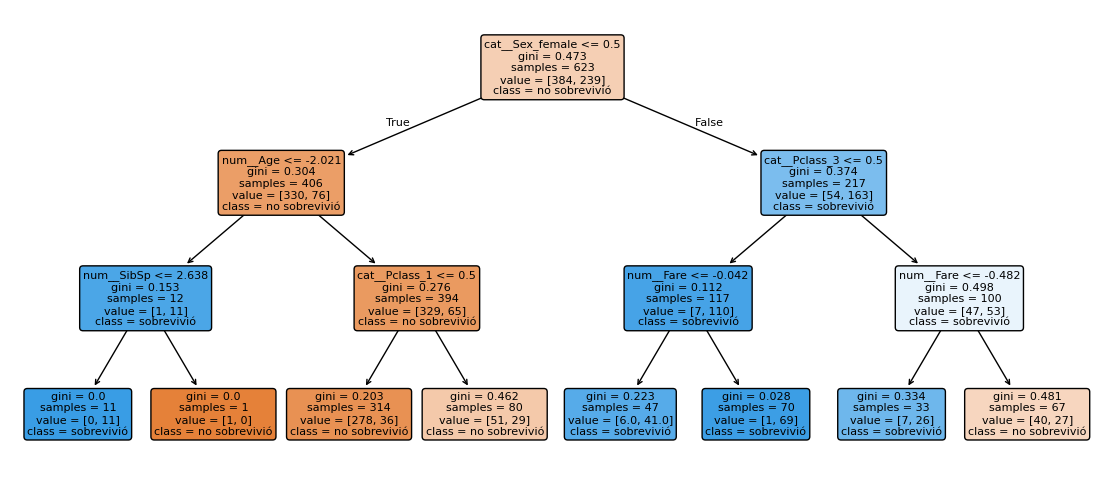

In [46]:
arbol = make_pipe(DecisionTreeClassifier(max_depth=3, random_state=0))
arbol.fit(X_train, y_train)
pred_arbol = arbol.predict(X_test)
print(f"Accuracy test: {accuracy_score(y_test, pred_arbol):.3f}")

plt.figure(figsize=(14, 6))
plot_tree(arbol.named_steps["modelo"], feature_names=nombres, class_names=["no sobrevivió", "sobrevivió"],
          filled=True, rounded=True, fontsize=8)
plt.show()

### 9.6 Evaluación: la matriz de confusión **es** una tabla de contingencia

Cruza lo real con lo predicho, igual que la tabla de la Parte 8.7. Así nacen precisión, recall y accuracy.

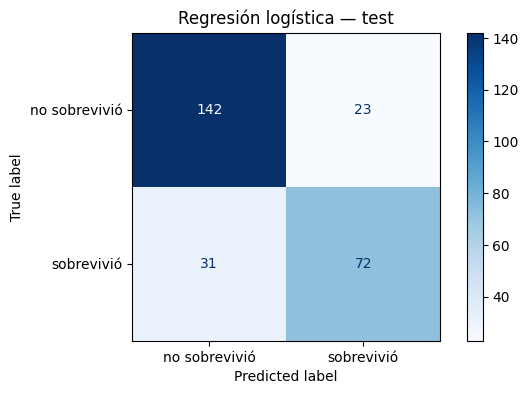

Accuracy  = (TP+TN)/total = 0.799
Precisión = TP/(TP+FP)    = 0.758   (de los que predije 'sobrevive', ¿cuántos sobrevivieron?)
Recall    = TP/(TP+FN)    = 0.699   (de los que sobrevivieron, ¿a cuántos detecté?)

χ² entre real y predicho: p = 0.0000  →  RECHAZO H0


In [47]:
cm = confusion_matrix(y_test, pred_logit)
ConfusionMatrixDisplay(cm, display_labels=["no sobrevivió", "sobrevivió"]).plot(cmap="Blues")
plt.title("Regresión logística — test"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Accuracy  = (TP+TN)/total = {(tp + tn) / cm.sum():.3f}")
print(f"Precisión = TP/(TP+FP)    = {tp / (tp + fp):.3f}   (de los que predije 'sobrevive', ¿cuántos sobrevivieron?)")
print(f"Recall    = TP/(TP+FN)    = {tp / (tp + fn):.3f}   (de los que sobrevivieron, ¿a cuántos detecté?)")

# ¿Predicción y realidad están asociadas? Es el chi² de la Parte 8.7
chi, p, _, _ = chi2_contingency(pd.crosstab(y_test, pred_logit))
print(f"\nχ² entre real y predicho: {decidir(p)}")

### 9.7 Incertidumbre sobre la accuracy (intervalo de confianza)

La accuracy en test es un **estadístico**: otra partición daría otro valor. Es una proporción, así que le podemos poner un IC como en la Parte 7:

In [48]:
acc = accuracy_score(y_test, pred_logit)
n_t = len(y_test)
e = norm.ppf(0.975) * np.sqrt(acc * (1 - acc) / n_t)
print(f"Accuracy = {acc:.3f}   IC 95 %: [{acc - e:.3f}, {acc + e:.3f}]   (n_test = {n_t})")
print(f"Baseline = {baseline:.3f}   → ¿el modelo es claramente mejor, o el intervalo se solapa?")

Accuracy = 0.799   IC 95 %: [0.750, 0.847]   (n_test = 268)
Baseline = 0.616   → ¿el modelo es claramente mejor, o el intervalo se solapa?


### Cierre conceptual

| Qué es | Ejemplos | ¿Quién lo fija? |
|---|---|---|
| Parámetros poblacionales | $\mu,\ \sigma,\ p$ | La realidad (desconocidos) |
| Estadísticos | $\bar x,\ s,\ \hat p$ | Los datos |
| Parámetros aprendidos | $\beta,\ w,\ b$ | El algoritmo |
| Hiperparámetros | `max_depth`, `C`, $k$ | Nosotros |

## Parte 10 — Sesgo

Hasta acá todo funcionó "demasiado bien". La palabra **sesgo** aparece en al menos cuatro lugares distintos de esta investigación y conviene no confundirlos:

| Tipo | Pregunta | ¿Se arregla con más datos? |
|---|---|---|
| **A. Sesgo del estimador** | ¿El cálculo se equivoca sistemáticamente? | Ya lo vimos en 7.1: se corrige con la fórmula |
| **B. Sesgo de muestreo / selección** | ¿La muestra representa a la población? | **No** |
| **C. Sesgo-varianza** (ML) | ¿El modelo es muy simple o muy complejo? | A veces |
| **D. Sesgo algorítmico** | ¿El modelo trata distinto a distintos grupos? | **No** |

---
### 10.A — Sesgo del estimador (recordatorio)

En 7.1, dividir por $n$ subestimaba $\sigma^2$ de forma sistemática. Eso es **sesgo en sentido estadístico**: $E[\hat\theta]-\theta\neq0$. Es el más "limpio": se mide y se corrige con matemática.

---
### 10.B — Sesgo de muestreo y de selección

Toda la inferencia (IC, tests, TCL) supone una **muestra aleatoria**. ¿Y si no lo es?

**Experimento:** solo una minoría de los pasajeros (~1 de cada 4) tiene registrada la cabina (`Cabin`). Imaginá que el estudio se hizo solo con esas personas ("muestra por conveniencia").

In [49]:
conocida = df["Cabin"].notna()
print(df.groupby(conocida)["Survived"].agg(tasa_supervivencia="mean", n="count"))
print("\nClase de los que tienen cabina registrada:")
print(df.loc[conocida, "Pclass"].value_counts(normalize=True).round(2))

       tasa_supervivencia    n
Cabin                         
False            0.299854  687
True             0.666667  204

Clase de los que tienen cabina registrada:
Pclass
1    0.86
2    0.08
3    0.06
Name: proportion, dtype: float64


Ahora hacemos exactamente lo de la Parte 7: IC al 95 % para la proporción de supervivientes, **pero muestreando solo entre quienes tienen cabina**. ¿Cuántas veces el intervalo captura la verdad?

In [50]:
p_real = df["Survived"].mean()
sub = df.loc[conocida, "Survived"].to_numpy()

for n_s in [30, 100]:
    reps, cubre = 2000, 0
    for _ in range(reps):
        m = rng.choice(sub, n_s, replace=False)
        ph = m.mean()
        se = np.sqrt(ph * (1 - ph) / n_s)
        cubre += (ph - 1.96 * se <= p_real <= ph + 1.96 * se)
    print(f"n = {n_s:3d}   cobertura del IC '95 %' = {cubre / reps:.1%}")

n =  30   cobertura del IC '95 %' = 6.5%
n = 100   cobertura del IC '95 %' = 0.0%


**La cobertura se desploma, y empeora con más datos.** El intervalo se hace más angosto alrededor de **el número equivocado**.

> 💡 *Más datos reducen la varianza, no el sesgo de selección.* Un tamaño de muestra enorme con un muestreo malo solo da una respuesta muy precisa y equivocada.

**Datos faltantes.** `Age` falta en ~20 % de las filas. ¿Falta al azar?

In [51]:
falta = df["Age"].isna()

print("Tasa de supervivencia según si falta Age:")
print(df.groupby(falta)["Survived"].mean().round(3), "\n")

tabla = pd.crosstab(falta, df["Pclass"], normalize="index").round(2)
print("Distribución de clase según si falta Age:\n", tabla, "\n")

chi, p, _, _ = chi2_contingency(pd.crosstab(falta, df["Pclass"]))
print("¿Faltar Age es independiente de la clase?", decidir(p))

# Imputar con la media "arregla" el vacío pero distorsiona la distribución
imputada = df["Age"].fillna(df["Age"].mean())
print(f"\nDesvío de Age original = {df['Age'].std():.2f}   |   tras imputar con la media = {imputada.std():.2f}")

Tasa de supervivencia según si falta Age:
Age
False    0.406
True     0.294
Name: Survived, dtype: float64 

Distribución de clase según si falta Age:
 Pclass     1     2     3
Age                     
False   0.26  0.24  0.50
True    0.17  0.06  0.77 

¿Faltar Age es independiente de la clase? p = 0.0000  →  RECHAZO H0

Desvío de Age original = 14.53   |   tras imputar con la media = 13.00


**Para pensar**

1. Si los faltantes se concentran en tercera clase, ¿qué pasa cuando hacemos `dropna()` y calculamos la edad media?
2. Imputar con la media achica el desvío. ¿Qué consecuencia tiene eso sobre el error estándar, los IC y los tests?
3. Las 891 filas que usamos son **una parte** de las personas que viajaban. ¿Quién quedó registrado y quién no? ¿Cómo condiciona eso lo que podemos afirmar? *(sesgo de supervivencia: la historia la cuentan los datos que quedaron)*

---
### 10.C — Sesgo-varianza: ¿modelo muy simple o muy complejo?

- **Sesgo alto (underfitting):** el modelo es demasiado simple, falla tanto en train como en test.
- **Varianza alta (overfitting):** el modelo memoriza el train y falla en datos nuevos.

`max_depth` controla ese equilibrio. Para elegirlo no usamos el test (eso sería hacer trampa): usamos **validación cruzada sobre train**.

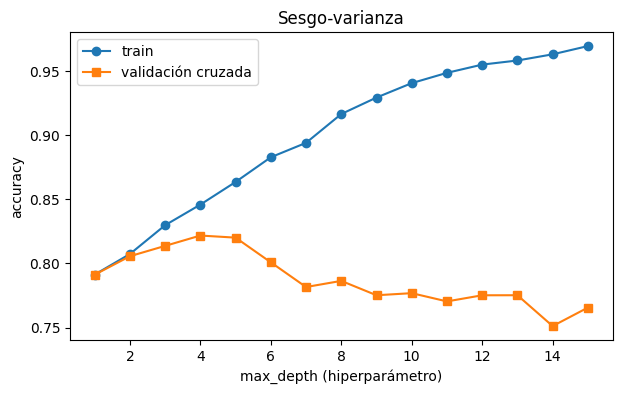

Mejor max_depth según validación: 4


In [52]:
profundidades = range(1, 16)
acc_train, acc_val = [], []

for d in profundidades:
    pipe = make_pipe(DecisionTreeClassifier(max_depth=d, random_state=0))
    pipe.fit(X_train, y_train)
    acc_train.append(pipe.score(X_train, y_train))
    acc_val.append(cross_val_score(pipe, X_train, y_train, cv=5).mean())

plt.plot(profundidades, acc_train, "o-", label="train")
plt.plot(profundidades, acc_val, "s-", label="validación cruzada")
plt.xlabel("max_depth (hiperparámetro)"); plt.ylabel("accuracy"); plt.legend()
plt.title("Sesgo-varianza"); plt.show()

mejor = profundidades[int(np.argmax(acc_val))]
print(f"Mejor max_depth según validación: {mejor}")

**Para pensar:** ¿en qué zona del gráfico está el *underfitting*? ¿Y el *overfitting*? ¿Qué le pasa a la brecha entre train y validación al crecer la profundidad?

---
### 10.D — Sesgo algorítmico: ¿a quién le falla el modelo?

Una accuracy global del ~80 % **oculta** cómo se reparten los errores. Medimos el desempeño **por grupo**:

- **Tasa predicha:** ¿a qué fracción del grupo el modelo le predice "sobrevive"? (paridad demográfica)
- **TPR (recall):** de los que realmente sobrevivieron, ¿a cuántos detecta?
- **FPR:** de los que no sobrevivieron, ¿a cuántos predice "sobrevive" por error?

In [53]:
def metricas_por_grupo(grupo, y_true, y_pred):
    grupo, y_true, y_pred = map(np.asarray, (grupo, y_true, y_pred))
    filas = []
    for g in np.unique(grupo):
        m = grupo == g
        yt, yp = y_true[m], y_pred[m]
        tp = ((yt == 1) & (yp == 1)).sum(); fn = ((yt == 1) & (yp == 0)).sum()
        fp = ((yt == 0) & (yp == 1)).sum(); tn = ((yt == 0) & (yp == 0)).sum()
        filas.append({
            "grupo": g, "n": m.sum(),
            "tasa_real": yt.mean(), "tasa_predicha": yp.mean(),
            "accuracy": (tp + tn) / m.sum(),
            "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
            "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        })
    return pd.DataFrame(filas).round(3)

print("Por sexo:")
display(metricas_por_grupo(X_test["Sex"], y_test, pred_logit))
print("Por clase:")
display(metricas_por_grupo(X_test["Pclass"], y_test, pred_logit))

Por sexo:


,grupo,n,tasa_real,tasa_predicha,accuracy,TPR,FPR
0,female,97,0.722,0.887,0.773,0.957,0.704
1,male,171,0.193,0.053,0.813,0.152,0.029


Por clase:


,grupo,n,tasa_real,tasa_predicha,accuracy,TPR,FPR
0,1,69,0.609,0.536,0.783,0.762,0.185
1,2,54,0.519,0.463,0.907,0.857,0.038
2,3,145,0.228,0.228,0.766,0.485,0.152


**Leé la tabla con calma.** ¿Hay grupos con TPR muy bajo (sobrevivientes que el modelo "no ve")? ¿Con FPR muy alto? La accuracy global promedia esas diferencias y las esconde.

**Pregunta clave:** el modelo aprendió que *ser mujer o viajar en primera* predice sobrevivir. ¿Descubrió una ley de la naturaleza, o **aprendió las reglas sociales de 1912** ("mujeres y niños primero", acceso a botes por clase)? Un modelo aprende el patrón de los datos aunque el patrón sea injusto.

### ¿Y si quitamos la variable sensible?

Intuición común: *"si no uso `Sex`, el modelo no discrimina por sexo"*. Probémoslo:

In [54]:
FEATURES_SIN_SEXO = [c for c in FEATURES if c != "Sex"]

logit_ns = make_pipe(LogisticRegression(max_iter=1000), features=FEATURES_SIN_SEXO)
logit_ns.fit(X_train[FEATURES_SIN_SEXO], y_train)
pred_ns = logit_ns.predict(X_test[FEATURES_SIN_SEXO])

print(f"Accuracy con Sex: {accuracy_score(y_test, pred_logit):.3f}   |   sin Sex: {accuracy_score(y_test, pred_ns):.3f}\n")
print("Por sexo, MODELO SIN la variable Sex:")
display(metricas_por_grupo(X_test["Sex"], y_test, pred_ns))

Accuracy con Sex: 0.799   |   sin Sex: 0.713

Por sexo, MODELO SIN la variable Sex:


,grupo,n,tasa_real,tasa_predicha,accuracy,TPR,FPR
0,female,97,0.722,0.392,0.629,0.514,0.074
1,male,171,0.193,0.234,0.760,0.485,0.174


**Para pensar**

1. Compará las dos tablas: ¿qué pasó con la accuracy global, con la tasa predicha por sexo y con el TPR de las mujeres? Otras variables (`Fare`, `Pclass`, `Parch`) pueden actuar como **proxies** del sexo. *Quitar la columna cambia el reparto de los errores, pero no lo vuelve automáticamente justo, y tiene un costo en desempeño.*
2. ¿Cómo comprobarías con una prueba de la Parte 8 si la predicción está asociada con el sexo? *(pista: $\chi^2$ de independencia entre `Sex` y `pred`)*
3. Hay varias definiciones de "justo" (misma tasa predicha, mismo TPR, mismo FPR). **No se pueden cumplir todas a la vez** si las tasas reales difieren entre grupos. ¿Cuál elegirías, y quién debería decidirlo?
4. Si este modelo se usara hoy para asignar recursos escasos, ¿sería aceptable? ¿Por qué un modelo "preciso" puede ser inaceptable?

---
### Resumen del sesgo

| Sesgo | Dónde apareció | Cómo se detecta | Cómo se mitiga |
|---|---|---|---|
| Del estimador | Varianza con $n$ vs. $n-1$ (7.1) | Simular y comparar $E[\hat\theta]$ con $\theta$ | Corregir la fórmula |
| De muestreo / selección | Muestra con cabina (10.B) | Cobertura del IC, comparar con la población | Mejor diseño de muestreo; **no** más $n$ |
| De datos faltantes | `Age` (10.B) | Test de independencia del faltante | Entender *por qué* falta; imputar con cuidado |
| Sesgo-varianza | `max_depth` (10.C) | Curvas train vs. validación | Elegir complejidad con CV |
| Algorítmico | Desempeño por sexo y clase (10.D) | Métricas **por grupo** | Auditar, revisar proxies, decidir criterios de equidad |

## Cierre: respondemos la pregunta madre

Escribí tu conclusión (5–8 líneas) respondiendo:

1. ¿Qué proporción sobrevivió y con qué incertidumbre? *(Parte 7)*
2. ¿Qué características están **asociadas** con la supervivencia, y con qué evidencia estadística? *(Parte 8)*
3. ¿Qué tan bien las predice un modelo sencillo y frente a qué baseline? *(Parte 9)*
4. ¿Qué límites tiene todo esto por cómo se armó la muestra y por cómo se reparte el error entre grupos? *(Parte 10)*

> **Asociación no es causalidad.** Que `Sex` esté asociado con `Survived` no significa que el sexo *cause* sobrevivir: refleja decisiones humanas, ubicación en el barco y acceso a los botes.

### Recorrido completo

$$\text{Titanic real}\to\text{variables}\to\text{probabilidad}\to\text{distribuciones}\to\text{descriptiva}\to\text{muestreo, LGN, TCL}\to\text{estimación e IC}\to\text{tests}\to\text{ML}\to\boxed{\text{sesgo}}$$